# 05 | Business Simulation & Targeting Policy

**Author:** Nguyen (Sue) Huynh  
**Last Updated:** June 2026

---

**Objectives**

This notebook translates the conditional average treatment effects (CATE) predicted by our top-performing model into actionable business strategies. We evaluate the economic viability of a budget-constrained targeting policy by comparing CATE-driven selection against traditional benchmarking approaches (random targeting and propensity-based targeting). Additionally, we run sensitivity analyses across varying marketing budgets and outcome value definitions to isolate the exact operational conditions required for profitable campaign execution.

# Executive Briefing: CATE-Driven Budget Allocation

### The Challenge (Situation & Complication)
Deploying a mass user-acquisition campaign across 25M prospects under a tight budget constraint results in severe financial loss if managed traditionally. A baseline strategy of random targeting under a $0.18 unit cost yields a devastating **-96% ROI**. Compounding this, a traditional machine learning approach targeting the highest "propensity to convert" underperforms because it wastes budget on "sure things" (users who would have converted anyway without receiving an incentive)

### The Solution (Resolution)
We developed a Heterogeneous Treatment Effect pipeline utilizing a **Causal Forest** estimator to model individual Conditional Average Treatment Effects (CATE). Instead of predicting *who will buy*, the model isolates *who will buy because of the intervention*. We then translated these treatment effects into an optimized, budget-constrained targeting policy.

### The Business Impact
* **Efficiency Frontier:** The CATE policy successfully extracts 2,291 incremental conversions out of a $10,000 budget, outperforming random allocation by **5.7x**.
* **Breakeven Optimization:** The policy drops the company’s structural breakeven floor to **$4.36 per conversion** at scale.
* **Profitability Realization:** On campaigns where customer value scales to $5.00, our framework converts a historical loss-leader into a profitable engine yielding a **+14.5% net ROI** at scale ($10k budget), and up to **+183% ROI** on highly surgical, low-budget spends ($1k budget).

## 1. Setup and Loading Policy

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from config.config import Config
from src.evaluation.targeting_policy import TargetingPolicy

from xgboost import XGBClassifier

In [2]:
# Load dataset
cfg = Config()

df_train = pd.read_parquet("../processed/train.parquet")
# df_val = pd.read_parquet("../processed/val.parquet")

X_train, t_train, y_train, y_secondary_train = df_train[cfg.feature_cols], df_train[cfg.treatment_col], df_train[cfg.outcome_col], df_train[cfg.secondary_outcome_col]
# X_val, t_val, y_val, y_secondary_val = df_val[cfg.feature_cols], df_val[cfg.treatment_col], df_val[cfg.outcome_col], df_val[cfg.secondary_outcome_col]

df_test = pd.read_parquet("../processed/test.parquet")
X_test, t_test, y_test, y_secondary_test = df_test[cfg.feature_cols], df_test[cfg.treatment_col], df_test[cfg.outcome_col], df_test[cfg.secondary_outcome_col]

In [3]:
# Calculate true tau_hat using causal forest
causalforest = joblib.load(cfg.models_dir / 'causalforest.joblib')
true_tau_hat = causalforest.predict_uplift(X_test)

c:\Users\nguye\uplift-modeling\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Initialize policy
policy = TargetingPolicy(budget=10000, cost_per_unit=0.18)

## 2. Baseline Policy Comparison

We initialize a baseline targeting scenario governed by clear operational constraints: a fixed marketing budget of **\$10,000** and a unit cost of **\$0.18 per treatment** (implying a maximum capacity of 55,555 targeted individuals). We evaluate three distinct assignment rules:
1. **CATE (Causal Forest):** Priorities individuals based on highest predicted incremental lift.
2. **Propensity:** Priorities individuals with the highest baseline probability of conversion.
3. **Random:** Selects individuals arbitrarily across the test set.

### 2.1 Random Targeting

In [5]:
rng = np.random.default_rng(cfg.random_state)
random_scores = rng.uniform(size=len(X_test))
result_random = policy.simulate_roi("random", random_scores, true_tau_hat, value_per_outcome=1.0)

### 2.2 Propensity Model

In [6]:
with open(cfg.data_dir / "scale_pos_weights.json", "r") as f:
    weights = json.load(f)

scale_pos_weight_visit = weights["scale_pos_weight_visit"]
response_model = XGBClassifier(**cfg.xgb_params, scale_pos_weight = scale_pos_weight_visit)
response_model.fit(X_train, y_train)
propensity_scores = response_model.predict_proba(X_test)[:, 1]

result_propensity = policy.simulate_roi("propensity", propensity_scores, true_tau_hat, value_per_outcome=1.0)

### 2.3 Causal Forest

In [7]:
result_cate = policy.simulate_roi("cate", true_tau_hat, true_tau_hat, value_per_outcome=1.0)

### 2.4 Insights

In [8]:
policy.compare_strategies([result_random, result_propensity, result_cate])

,strategy,n_targeted,total_value_gained,total_cost,roi
0,cate,55555,2291.437646,9999.9,-0.770854
1,propensity,55555,2167.480624,9999.9,-0.783250
2,random,55555,399.457152,9999.9,-0.960054


**Causal Dominance over Random Assignment:** The CATE-driven policy captures 2,291.44 incremental conversions, outperforming random targeting by a factor of 5.7x. This confirms that the Causal Forest model succeeds at capturing genuine positive treatment effects within the data.

**The Pitfall of Propensity Targeting:** Propensity-based targeting yields fewer incremental conversions (2,167.48) than the CATE approach. This mathematically demonstrates the "sure thing" problem: targeting individuals who are highly likely to convert anyway wastes budget on individuals who do not require an incentive, underperforming a true lift-based policy.

**The Unit Value Deficit:** At an outcome value of $1.00, all strategies yield a negative ROI. This reveals that while the Causal Forest maximizes conversion volume, a baseline unit value of $1.00 is commercially unviable given the $0.18 marginal cost of treatment.

## 3. Policy Sensitivity Analysis
To determine how the CATE policy scales and when it achieves profitability, we execute three distinct business simulations using the Causal Forest pipeline.

### 3.1 Simulation 1: Budget Variation (Diminishing Returns)
We vary the total marketing budget from $1,000 to $10,000 while maintaining a fixed conversion value position ($V = \$1.00$). The breakeven value is dynamically computed as $\text{Budget} / \text{Incremental Conversions}$.

In [75]:
min_budget = 1000
max_budget = 10000
step_budget = 1000
len_budget = int((max_budget - min_budget) / step_budget) + 1

budget_sim = pd.DataFrame(
    {
        "budget": np.arange(min_budget, max_budget + step_budget, step_budget),
        "value_gain": np.ones(len_budget),
        "value_per_outcome": np.ones(len_budget),
        "roi": np.ones(len_budget),
        "breakeven_value": np.ones(len_budget)
    }
)

In [76]:
for i, row in budget_sim.iterrows():
    policy = TargetingPolicy(budget=row["budget"], cost_per_unit=0.18)
    result_cate = policy.simulate_roi("cate", true_tau_hat, true_tau_hat, value_per_outcome=1.0)
    budget_sim.at[i, "value_gain"] = result_cate.total_value_gained
    budget_sim.at[i, "roi"] = result_cate.roi
    budget_sim.at[i, "breakeven_value"] = row["budget"] / result_cate.total_value_gained
budget_sim

,budget,value_gain,value_per_outcome,roi,breakeven_value
0,1000,564.895928,1.0,-0.435048,1.770238
1,2000,939.721462,1.0,-0.530135,2.128290
2,3000,1228.908442,1.0,-0.590347,2.441191
3,4000,1467.290886,1.0,-0.633174,2.726112
4,5000,1667.044600,1.0,-0.666582,2.999320
5,6000,1836.790936,1.0,-0.693865,3.266567
6,7000,1980.783736,1.0,-0.717024,3.533955
7,8000,2102.518988,1.0,-0.737182,3.804960
8,9000,2204.988288,1.0,-0.755001,4.081654
9,10000,2291.437646,1.0,-0.770854,4.364072


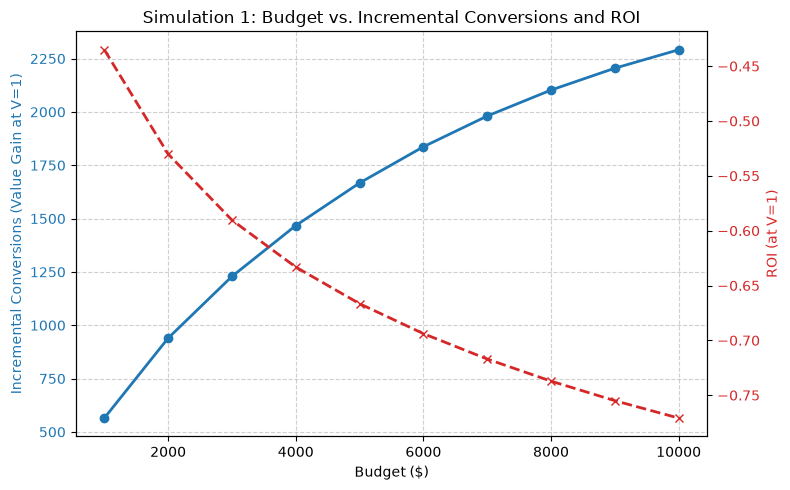

In [77]:
# Plot 1: Simulation 1 - Diminishing Returns and ROI
fig, ax1 = plt.subplots(figsize=(8, 5))
color = 'tab:blue'
ax1.set_xlabel('Budget ($)')
ax1.set_ylabel('Incremental Conversions (Value Gain at V=1)', color=color)
ax1.plot(budget_sim['budget'], budget_sim['value_gain'], marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('ROI (at V=1)', color=color)
ax2.plot(budget_sim['budget'], budget_sim['roi'], marker='x', color=color, linestyle='--', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Simulation 1: Budget vs. Incremental Conversions and ROI')
fig.tight_layout()
plt.savefig('../results/simulation1_budget_impact.png', dpi=300)
plt.show()

**Insights:**

**Clear Evidence of Diminishing Marginal Returns:** Expanding the budget by 10x (from $1,000 to $10,000) only yields a 4x increase in incremental conversions. Because the policy intelligently targets the highest-lift individuals first, subsequent budget expansions force the policy to target less responsive cohorts, resulting in a steadily decaying ROI curve.

**Escalating Breakeven Thresholds:** Due to diminishing returns, the necessary conversion value required to break even rises from $1.77 at a small $1,000 spend to $4.36 at a $10,000 spend. Smaller campaigns can be sustained with lower-value products, whereas aggressive scaling requires higher customer lifetime values (LTV).

### 3.2 Simulation 2: Outcome Value Variation
Holding the budget constant at $10,000 (locking the targeted cohort to the top 55,555 users), we scale the individual economic value of a conversion from $1.00 to $5.00 to find the profitability crossover point.

In [93]:
min_value = 1
max_value = 5
step_value = 0.5
len_value = int((max_value - min_value) / step_value) + 1

result_cate = policy.simulate_roi("cate", true_tau_hat, true_tau_hat, value_per_outcome=1.0)
breakeven_value = 10000 / result_cate.total_value_gained

value_sim = pd.DataFrame(
    {
        "value_per_outcome": np.arange(min_value, max_value + step_value, step_value),
        "value_gain": np.ones(len_value),
        "budget":np.full(len_value, 10000),
        "roi": np.ones(len_value),
        "breakeven_value": np.full(len_value, breakeven_value) 
    }
)

In [94]:
for i, row in value_sim.iterrows():
    policy = TargetingPolicy(budget=row["budget"], cost_per_unit=0.18)
    result_cate = policy.simulate_roi("cate", true_tau_hat, true_tau_hat, value_per_outcome=row["value_per_outcome"])
    value_sim.at[i, "value_gain"] = result_cate.total_value_gained
    value_sim.at[i, "roi"] = result_cate.roi
value_sim

,value_per_outcome,value_gain,budget,roi,breakeven_value
0,1.0,2291.437646,10000,-0.770854,4.364072
1,1.5,3437.156468,10000,-0.656281,4.364072
2,2.0,4582.875291,10000,-0.541708,4.364072
3,2.5,5728.594114,10000,-0.427135,4.364072
4,3.0,6874.312937,10000,-0.312562,4.364072
5,3.5,8020.031760,10000,-0.197989,4.364072
6,4.0,9165.750582,10000,-0.083416,4.364072
7,4.5,10311.469405,10000,0.031157,4.364072
8,5.0,11457.188228,10000,0.145730,4.364072


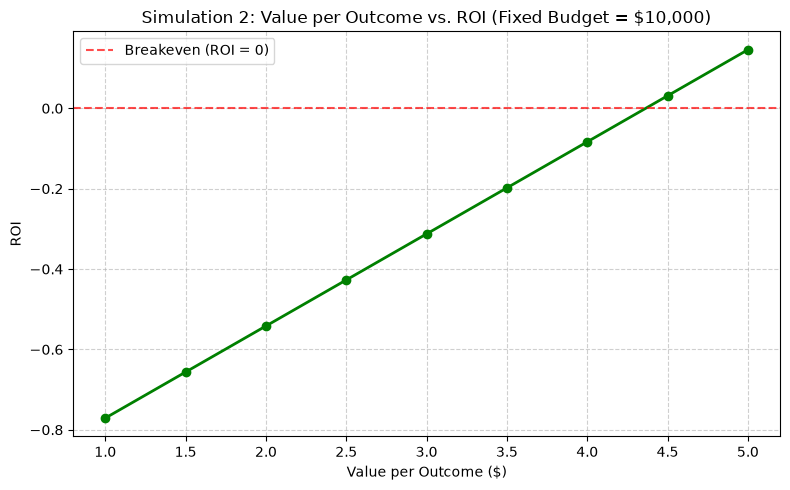

In [81]:
# Plot 2: Simulation 2 - Value per Outcome vs ROI
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(value_sim['value_per_outcome'], value_sim['roi'], marker='o', color='green', linewidth=2)
ax.axhline(0, color='red', linestyle='--', alpha=0.7, label='Breakeven (ROI = 0)')
ax.set_xlabel('Value per Outcome ($)')
ax.set_ylabel('ROI')
ax.set_title('Simulation 2: Value per Outcome vs. ROI (Fixed Budget = $10,000)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
fig.tight_layout()
plt.savefig('../results/simulation2_value_impact.png', dpi=300)
plt.show()

**Insights:**

**The Crossover Horizon:** Because the selected cohort is static, the financial return scales linearly with the unit value. The policy crosses the threshold into net-positive profitability ($ROI > 0$) precisely between the $4.00 and $4.50 value positions, validating our previously modeled breakeven constant of $4.36.

### 3.3 Simulation 3: Joint Frontier Optimization (ROI > 0)

To locate the most efficient combination of scale and margin, we map out the complete multi-dimensional parameter grid, filtering exclusively for parameter pairs that guarantee a strictly positive net return ($ROI > 0$).

In [82]:
min_budget = 1000
max_budget = 10000
step_budget = 1000
len_budget = int((max_budget - min_budget) / step_budget) + 1

min_value = 1
max_value = 5
step_value = 0.5
len_value = int((max_value - min_value) / step_value) + 1

budgets = np.arange(min_budget, max_budget + step_budget, step_budget)
values = np.arange(min_value, max_value + step_value, step_value)

df_budgets = pd.DataFrame({'budget': budgets})
df_values = pd.DataFrame({'value_per_outcome': values})


budget_value_sim = pd.merge(df_budgets, df_values, how='cross')
budget_value_sim["value_gain"] = 1.0
budget_value_sim["roi"] = 1.0

In [83]:
for i, row in budget_value_sim.iterrows():
    policy = TargetingPolicy(budget=row["budget"], cost_per_unit=0.18)
    result_cate = policy.simulate_roi("cate", true_tau_hat, true_tau_hat, value_per_outcome=row["value_per_outcome"])
    budget_value_sim.at[i, "value_gain"] = result_cate.total_value_gained
    budget_value_sim.at[i, "roi"] = result_cate.roi
    
budget_value_sim

,budget,value_per_outcome,value_gain,roi
0,1000,1.0,564.895928,-0.435048
1,1000,1.5,847.343891,-0.152571
2,1000,2.0,1129.791855,0.129905
3,1000,2.5,1412.239819,0.412381
4,1000,3.0,1694.687783,0.694857
...,...,...,...,...
85,10000,3.0,6874.312937,-0.312562
86,10000,3.5,8020.031760,-0.197989
87,10000,4.0,9165.750582,-0.083416
88,10000,4.5,10311.469405,0.031157


In [84]:
df_profitable = budget_value_sim[budget_value_sim["roi"] > 0.0]
df_profitable.sort_values(by=["roi"], ascending=False).head()

,budget,value_per_outcome,value_gain,roi
8,1000,5.0,2824.479638,1.824762
7,1000,4.5,2542.031674,1.542286
17,2000,5.0,4698.607310,1.349327
6,1000,4.0,2259.583711,1.259810
16,2000,4.5,4228.746579,1.114394


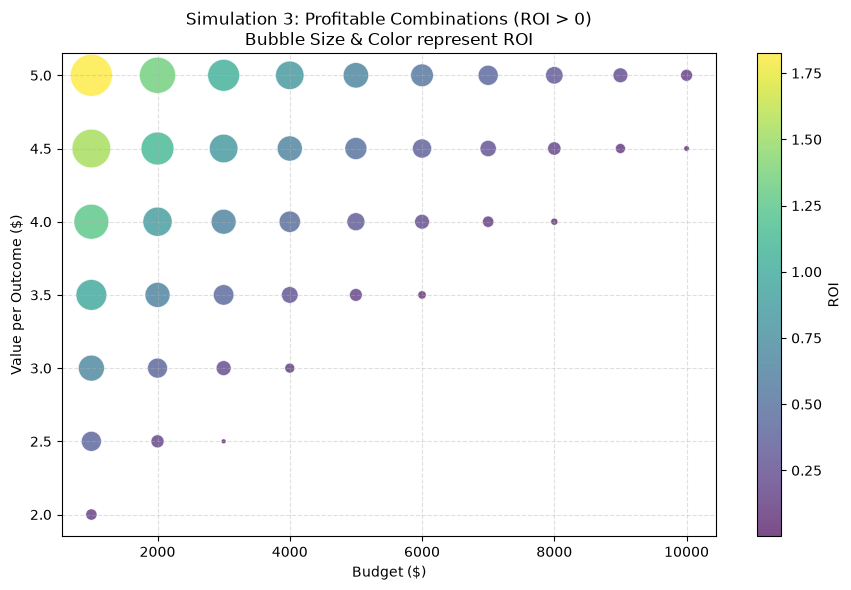

Number of profitable combinations: 43


In [85]:
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(
    df_profitable['budget'], 
    df_profitable['value_per_outcome'], 
    s=df_profitable['roi'] * 500, # Scale for visibility
    c=df_profitable['roi'], 
    cmap='viridis', 
    alpha=0.7, 
    edgecolors='w', 
    linewidth=0.5
)
ax.set_xlabel('Budget ($)')
ax.set_ylabel('Value per Outcome ($)')
ax.set_title('Simulation 3: Profitable Combinations (ROI > 0)\nBubble Size & Color represent ROI')
fig.colorbar(scatter, label='ROI')
ax.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
plt.savefig('../results/simulation3_profitable_bubble.png', dpi=300)
plt.show()

print(f"Number of profitable combinations: {len(df_profitable)}")

**Insights:**

**The Efficiency Frontier:** The bubble plot demonstrates that maximum ROI density occurs at the intersection of a low budget ($1,000) and a high outcome value ($5.00), reaching an optimal peak ROI of ~183%.

**Strategic Operational Tradeoffs**: Management faces an explicit tradeoff between localized efficiency and absolute volume. If the corporate objective is pure margin optimization, the policy should be restricted to a tight, high-tier budget spend ($1,000–$2,000) where the Causal Forest targets only hyper-responsive "persuadables". If the goal is maximizing total value generation, larger budgets can be deployed safely, provided the margins support a minimum unit value of $4.50.